# Data Mining Project - Seller-Level Vehicle Listings Dataset

**Course:** Data Mining: Fundamental - University of Pisa

**Goal:** predict `seller_rating_class` (low / medium / high) from the aggregated seller-level features.

# 1. Data Understanding & Preparation

This section describes the supplied data, examines distributions and quality, and prepares a reproducible feature representation. The original CSV is kept unchanged. Decisions are based on the accompanying variable description and the observations shown below.

After the initial schema inspection, 20% of the records are reserved for later classification evaluation. Distribution analysis and choices about preprocessing use the remaining 80%. No predictive model is fitted in this section.

## 1.1 Data semantics

The dataset describes sellers and their vehicle inventories. We first identify what each column represents and distinguish its meaning from its Python storage type.

Definitions come from the supplied seller_level_vehicle_dataset_description.txt. The measurement scales follow the course's Data Understanding lecture, slides 12–15. Applying those scales to the documented variables is our interpretation.

Run the cells in order. Distribution analysis follows in Section 1.2.

### 1.1.1 Load the original data

In [1]:
from pathlib import Path
import pandas as pd

data_path = Path("dataset") / "seller_info_dm1_2627.csv"
if not data_path.exists():
    data_path = Path("project") / data_path
df = pd.read_csv(data_path)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 13843
Columns: 33


In [2]:
df.head(3)

,sp_id,n_listings,price_median,savings_amount_median,daysonmarket_median,mileage_median,year_median,vehicle_age_median,owner_count_median,horsepower_median,engine_displacement_median,city_fuel_economy_median,highway_fuel_economy_median,back_legroom_median,front_legroom_median,fuel_tank_volume_median,height_median,length_median,width_median,pct_isCab,pct_is_new,pct_salvage,pct_theft_title,n_listing_days,listing_span_days,dominant_body_type,dominant_fuel_type,dominant_transmission,dominant_wheel_system,dominant_listing_color,franchise_status,new_used_profile,seller_rating_class
0,404771.0,30,6700.0,431.0,13.0,193193.5,2011.0,9.0,2.0,258.5,NaN,17.0,23.5,38.65,41.3,21.0,68.9,195.35,77.1,0.133333,0.0,0.0,0.0,15,156,suv_crossover,gasoline,a,NaN,gray,independent,used_only,medium
1,336590.0,17,10995.0,505.0,24.0,87589.0,2012.0,7.0,2.0,182.0,2400.0,21.0,28.5,37.30,41.4,15.9,64.7,180.30,72.5,0.058824,0.0,0.0,0.0,14,589,suv_crossover,gasoline,a,awd,silver,independent,used_only,medium
2,392016.0,18,7645.0,632.0,43.0,151434.0,2010.5,9.5,2.0,205.0,NaN,20.0,28.5,35.50,41.7,17.5,58.1,188.20,72.0,0.111111,0.0,0.0,0.0,15,97,sedan,gasoline,a,NaN,blue,independent,used_only,low


Each row is intended to represent one seller, identified by sp_id. Vehicle characteristics have been aggregated within the seller's inventory. The preview shows how the definitions appear in the file; it does not establish that every record is valid.

### 1.1.2 Inspect storage types

In [3]:
storage_types = df.dtypes.astype(str).rename("pandas_dtype")
storage_types.to_frame()

,pandas_dtype
sp_id,float64
n_listings,int64
price_median,float64
savings_amount_median,float64
daysonmarket_median,float64
mileage_median,float64
year_median,float64
vehicle_age_median,float64
owner_count_median,float64
horsepower_median,float64


A storage type describes how pandas represents a column, rather than its analytical meaning. Here, sp_id is stored as float64, although its documented role is an identifier.

Text columns may appear as str, object or a string extension type depending on the pandas version and loading options. Floating-point storage does not prove that the underlying concept is continuous.

### 1.1.3 Build the variable dictionary

In [4]:
variable_definitions = [
    ('sp_id', 'Seller/dealer identifier', 'Nominal identifier', 'Nominal', 'Not applicable', 'Identifier'),
    ('n_listings', 'Number of listings associated with the seller', 'Numeric count', 'Ratio', 'Listings', 'Feature'),
    ('price_median', 'Median advertised vehicle price', 'Numeric median', 'Ratio', 'Currency not specified', 'Feature'),
    ('savings_amount_median', 'Median advertised savings amount', 'Numeric median', 'Ratio', 'Currency not specified', 'Feature'),
    ('daysonmarket_median', 'Median time that vehicles remained listed', 'Numeric median', 'Ratio', 'Days', 'Feature'),
    ('mileage_median', 'Median vehicle mileage', 'Numeric median', 'Ratio', 'Distance unit not specified', 'Feature'),
    ('year_median', 'Median vehicle model year', 'Numeric median', 'Interval', 'Calendar year', 'Feature'),
    ('vehicle_age_median', 'Median vehicle age at listing: listing year minus model year', 'Numeric median', 'Ratio', 'Years', 'Feature'),
    ('owner_count_median', 'Median number of previous vehicle owners', 'Numeric median', 'Ratio', 'Owners', 'Feature'),
    ('horsepower_median', 'Median vehicle horsepower', 'Numeric median', 'Ratio', 'Horsepower; convention not specified', 'Feature'),
    ('engine_displacement_median', 'Median engine displacement', 'Numeric median', 'Ratio', 'Volume unit not specified', 'Feature'),
    ('city_fuel_economy_median', 'Median city fuel economy', 'Numeric median', 'Ratio', 'Fuel economy unit not specified', 'Feature'),
    ('highway_fuel_economy_median', 'Median highway fuel economy', 'Numeric median', 'Ratio', 'Fuel economy unit not specified', 'Feature'),
    ('back_legroom_median', 'Median rear-seat legroom', 'Numeric median', 'Ratio', 'Length unit not specified', 'Feature'),
    ('front_legroom_median', 'Median front-seat legroom', 'Numeric median', 'Ratio', 'Length unit not specified', 'Feature'),
    ('fuel_tank_volume_median', 'Median fuel-tank capacity', 'Numeric median', 'Ratio', 'Volume unit not specified', 'Feature'),
    ('height_median', 'Median vehicle height', 'Numeric median', 'Ratio', 'Length unit not specified', 'Feature'),
    ('length_median', 'Median vehicle length', 'Numeric median', 'Ratio', 'Length unit not specified', 'Feature'),
    ('width_median', 'Median vehicle width', 'Numeric median', 'Ratio', 'Length unit not specified', 'Feature'),
    ('pct_isCab', 'Proportion of listed vehicles previously used as taxis or cabs', 'Numeric proportion', 'Ratio', 'Proportion', 'Feature'),
    ('pct_is_new', 'Proportion of listed vehicles classified as new', 'Numeric proportion', 'Ratio', 'Proportion', 'Feature'),
    ('pct_salvage', 'Proportion of listed vehicles with salvage status', 'Numeric proportion', 'Ratio', 'Proportion', 'Feature'),
    ('pct_theft_title', 'Proportion of listed vehicles with a theft-related title', 'Numeric proportion', 'Ratio', 'Proportion', 'Feature'),
    ('n_listing_days', 'Number of distinct calendar days with observed listings', 'Numeric count', 'Ratio', 'Days', 'Feature'),
    ('listing_span_days', 'Time between the earliest and latest observed listing', 'Numeric duration', 'Ratio', 'Days', 'Feature'),
    ('dominant_body_type', 'Most common vehicle body type', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('dominant_fuel_type', 'Most common vehicle fuel type', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('dominant_transmission', 'Most common vehicle transmission type', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('dominant_wheel_system', 'Most common drivetrain or wheel-system configuration', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('dominant_listing_color', 'Most common standardized exterior color', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('franchise_status', 'Seller category derived from the proportion of franchise-associated listings', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('new_used_profile', 'Seller inventory profile with respect to new and used vehicles', 'Categorical', 'Nominal', 'Category label', 'Feature'),
    ('seller_rating_class', 'Discretized seller rating: low, medium or high', 'Categorical', 'Ordinal', 'Ordered category label', 'Target'),
]

dictionary_columns = [
    "variable", "meaning", "semantic_type", "measurement_scale", "unit", "role"
]

variable_dictionary = pd.DataFrame(
    variable_definitions,
    columns=dictionary_columns
).set_index("variable")

variable_dictionary = variable_dictionary.join(storage_types)
variable_dictionary

,meaning,semantic_type,measurement_scale,unit,role,pandas_dtype
variable,,,,,,
sp_id,Seller/dealer identifier,Nominal identifier,Nominal,Not applicable,Identifier,float64
n_listings,Number of listings associated with the seller,Numeric count,Ratio,Listings,Feature,int64
price_median,Median advertised vehicle price,Numeric median,Ratio,Currency not specified,Feature,float64
savings_amount_median,Median advertised savings amount,Numeric median,Ratio,Currency not specified,Feature,float64
daysonmarket_median,Median time that vehicles remained listed,Numeric median,Ratio,Days,Feature,float64
mileage_median,Median vehicle mileage,Numeric median,Ratio,Distance unit not specified,Feature,float64
year_median,Median vehicle model year,Numeric median,Interval,Calendar year,Feature,float64
vehicle_age_median,Median vehicle age at listing: listing year minus model year,Numeric median,Ratio,Years,Feature,float64
owner_count_median,Median number of previous vehicle owners,Numeric median,Ratio,Owners,Feature,float64


There are 24 numerical summaries, seven nominal categorical features, one ordinal target and one identifier. The numerical summaries comprise 17 medians, four proportions and three listing-activity measures.

Median model year is treated as interval-scaled: differences between years are meaningful, whereas ratios of calendar years are not. The other numerical summaries are treated as ratio-scaled based on their definitions as amounts, counts, durations, physical quantities or proportions. These assignments describe intended variables, not the validity of every observed value.

The rating labels have the order low < medium < high, but no numerical distances between classes are given. A dominant category is the most frequent category; it need not account for more than half of the inventory.

In [5]:
undocumented_columns = df.columns.difference(variable_dictionary.index)
extra_definitions = variable_dictionary.index.difference(df.columns)

print("Columns without a definition:", undocumented_columns.tolist())
print("Definitions without a column:", extra_definitions.tolist())

Columns without a definition: []
Definitions without a column: []


Both lists should be empty. This checks column coverage, not whether every definition or data value is correct.

### 1.1.4 Read the observed category labels

In [6]:
category_columns = [
    "dominant_body_type",
    "dominant_fuel_type",
    "dominant_transmission",
    "dominant_wheel_system",
    "dominant_listing_color",
    "franchise_status",
    "new_used_profile",
    "seller_rating_class"
]

for column in category_columns:
    labels = sorted(df[column].dropna().unique().tolist())
    print(column, ":", labels)

dominant_body_type : ['convertible', 'coupe', 'hatchback', 'minivan', 'pickup_truck', 'sedan', 'suv_crossover', 'van', 'wagon']
dominant_fuel_type : ['biodiesel', 'diesel', 'electric', 'flex_fuel_vehicle', 'gasoline', 'hybrid', 'unknown']
dominant_transmission : ['a', 'cvt', 'm', 'unknown']
dominant_wheel_system : ['4wd', '4x2', 'awd', 'fwd', 'rwd']
dominant_listing_color : ['black', 'blue', 'brown', 'gold', 'gray', 'green', 'red', 'silver', 'teal', 'unknown', 'white']
franchise_status : ['franchise', 'independent']
new_used_profile : ['mixed', 'new_only', 'used_only']
seller_rating_class : ['high', 'low', 'medium']


The labels are read directly from the CSV. Their alphabetical display order does not imply an analytical ordering. Codes such as a, cvt, m and awd are retained as supplied because the description does not define each code.
The description allows franchise, independent, mixed and unknown for franchise_status; the non-missing labels observed here are franchise and independent. For new_used_profile, it allows new_only, used_only, mixed and unknown; the observed labels are mixed, new_only and used_only. An allowed category need not occur in this file.

The literal label unknown remains a category in this inspection. dropna() excludes missing entries only from the temporary list of labels. It does not remove rows from df or decide how missing data should be handled.

### 1.1.5 Check how a median year can be represented

In [7]:
median_example = pd.Series([2010, 2011]).median()
print("Illustrative median of 2010 and 2011:", median_example)

fractional_years = df["year_median"].dropna()
fractional_years = fractional_years[fractional_years % 1 != 0]

fractional_years.head(5)

Illustrative median of 2010 and 2011: 2010.5


2     2010.5
4     2007.5
26    2014.5
34    2019.5
43    2008.5
Name: year_median, dtype: float64

The two-year example is illustrative, not a reconstruction of a seller's vehicles. The median of 2010 and 2011 is 2010.5. The CSV also contains fractional median years. A fractional value alone is therefore not sufficient evidence of an error and is not rounded here. The same principle applies to medians of counts, such as previous-owner counts.

Vehicle age refers to age at listing. The current calendar year should not be substituted into its definition. A median of differences is also not generally equal to a difference of medians.

### 1.1.6 Information not specified in the supplied description

- Several currency, distance, length, volume and fuel-economy units are not explicitly documented.
- Boundaries used to create the seller-rating classes are not provided.
- Rules for resolving ties in dominant categories and handling missing vehicle-level values during aggregation are not provided.
- Exact proportion thresholds used to assign franchise_status are not provided.
- The pct_ fields are described as proportions, with an intended interpretation as shares between 0 and 1. The prefix alone does not establish how every value has been stored.

These points remain open. Data-quality checks below use only documented or general mathematical constraints.

### Sources for variable definitions

1. Supplied dataset/seller_info_dm1_2627.csv and dataset/seller_level_vehicle_dataset_description.txt.
2. Course lecture: 01_dm1_data_understanding_2025_26.pdf, slides 12–15.
3. Assignment: dm1_project_guidelines_26_27.pptx.pdf, slide 7.


The dictionary's scales are interpretations of the documented meanings using course definitions. Missing units and code definitions have not been filled in from external domain knowledge.

## 1.2 Distribution of variables and statistics

### 1.2.1 Working sample and reserved test set

We reserve 20% of sellers with a fixed random seed. Stratification keeps the three rating classes in similar proportions in both subsets. The training sample is used for the descriptive analysis below; the test features are only transformed with the fitted rules at the end. The initial shape, dictionary and category inspection in 1.1 covered the whole file, so this is a development holdout rather than a completely unseen external dataset.

This split is for the later classification task. A future clustering analysis can fit a separate preprocessing instance on all sellers, without the rating target. A future regression task must also exclude its own chosen target from the inputs.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler, MinMaxScaler

RANDOM_STATE = 42
TARGET = "seller_rating_class"
ID_COLUMN = "sp_id"
RATING_ORDER = ["low", "medium", "high"]

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 12)

raw_df = df.copy(deep=True)

assert df[ID_COLUMN].notna().all()
assert df[ID_COLUMN].is_unique
assert df[TARGET].isin(RATING_ORDER).all()

train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=RANDOM_STATE, stratify=df[TARGET]
)
train_df = train_df.copy()
test_df = test_df.copy()

numeric_columns = df.select_dtypes(include="number").columns.drop(ID_COLUMN).tolist()
categorical_columns = [c for c in category_columns if c != TARGET]

print("Training records:", len(train_df))
print("Reserved test records:", len(test_df))
print("Versions:", "pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

Training records: 11074
Reserved test records: 2769
Versions: pandas 3.0.6 | scikit-learn 1.9.1


,all_records,training,reserved_test
seller_rating_class,,,
low,2579,2063,516
medium,7577,6061,1516
high,3687,2950,737


,count,percent
seller_rating_class,,
low,2063,18.63
medium,6061,54.73
high,2950,26.64


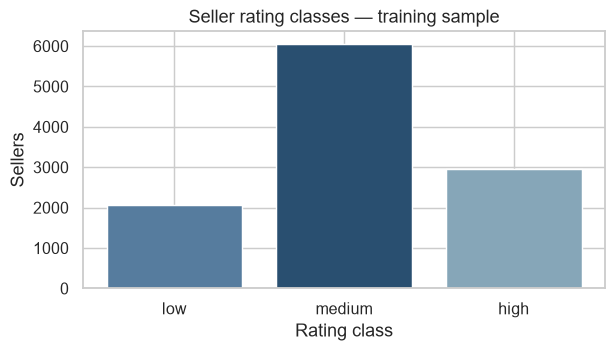

In [9]:
split_summary = pd.DataFrame({
    "all_records": df[TARGET].value_counts().reindex(RATING_ORDER),
    "training": train_df[TARGET].value_counts().reindex(RATING_ORDER),
    "reserved_test": test_df[TARGET].value_counts().reindex(RATING_ORDER)
})
display(split_summary)

target_summary = train_df[TARGET].value_counts().reindex(RATING_ORDER).to_frame("count")
target_summary["percent"] = target_summary["count"] / len(train_df) * 100
display(target_summary.round(2))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(target_summary.index, target_summary["count"], color=["#567c9e", "#294f70", "#86a6b8"])
ax.set(title="Seller rating classes — training sample", xlabel="Rating class", ylabel="Sellers")
fig.tight_layout()
plt.show()

The medium class accounts for about 55% of the training sample, while low is the smallest class. This is an imbalance to account for when evaluating classification later: a majority-class baseline and per-class metrics will be needed. No resampling is applied during data understanding.

### 1.2.2 Numerical distributions

In [10]:
numeric_summary = train_df[numeric_columns].describe().T
numeric_summary["missing"] = train_df[numeric_columns].isna().sum()
numeric_summary["skewness"] = train_df[numeric_columns].skew()
display(numeric_summary.round(3))

,count,mean,std,min,25%,50%,75%,max,missing,skewness
n_listings,11074.0,117.991,137.832,5.00,25.000,70.000,168.000,4959.000,0,5.878
price_median,11074.0,23183.770,14403.052,1699.00,12495.000,22481.000,29884.625,229888.000,0,3.335
savings_amount_median,11074.0,446.696,524.232,0.00,0.000,356.250,731.750,9333.000,0,2.572
daysonmarket_median,11074.0,49.147,57.391,0.00,26.000,36.000,51.000,1987.000,0,9.359
mileage_median,11073.0,51165.537,51631.045,0.00,25.000,33322.000,96650.000,238541.000,1,0.683
year_median,11074.0,2015.965,4.705,1960.00,2013.000,2017.000,2020.000,2021.000,0,-2.265
vehicle_age_median,11073.0,4.067,4.619,0.00,0.000,3.000,7.000,60.000,1,2.347
owner_count_median,11045.0,1.429,0.617,1.00,1.000,1.000,2.000,6.000,29,1.275
horsepower_median,11070.0,240.965,57.269,78.00,188.000,242.750,283.000,630.000,4,0.866
engine_displacement_median,8363.0,2922.552,807.960,1200.00,2400.000,2500.000,3500.000,6800.000,2711,1.316


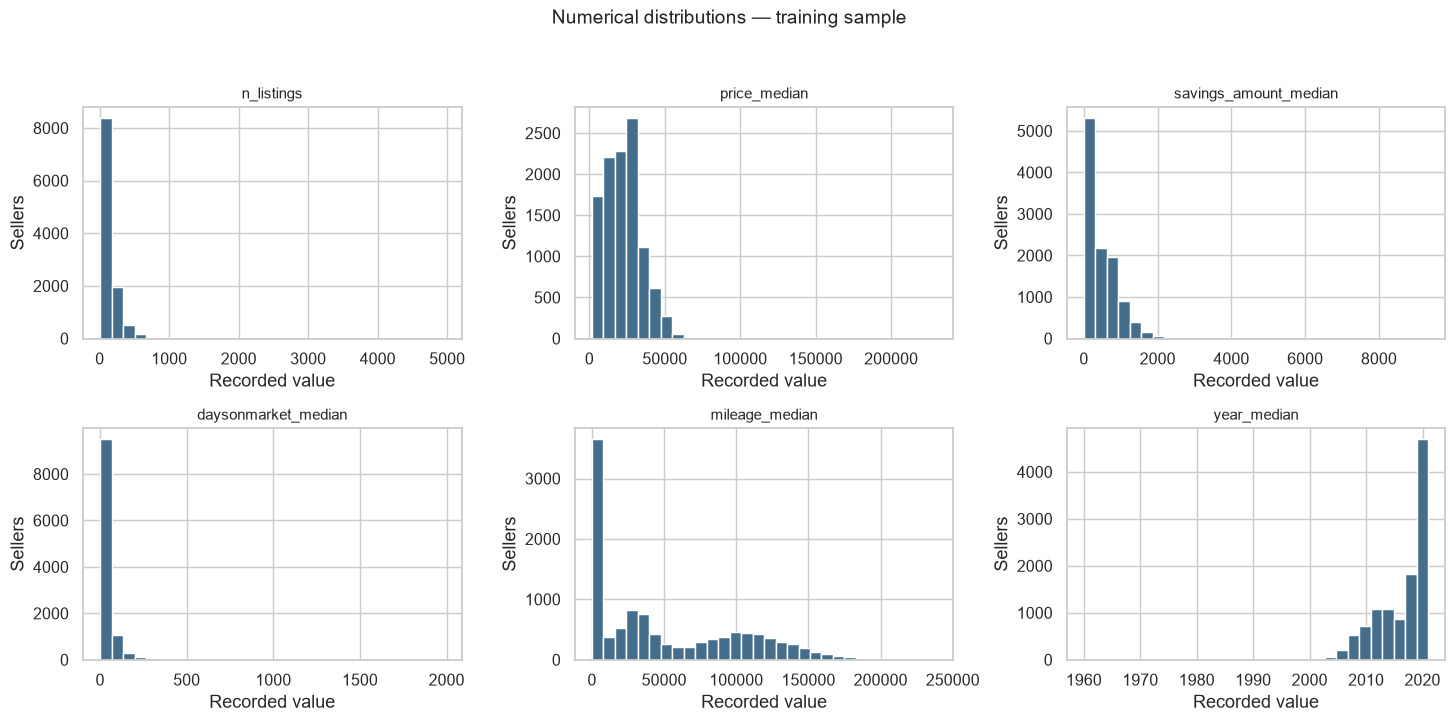

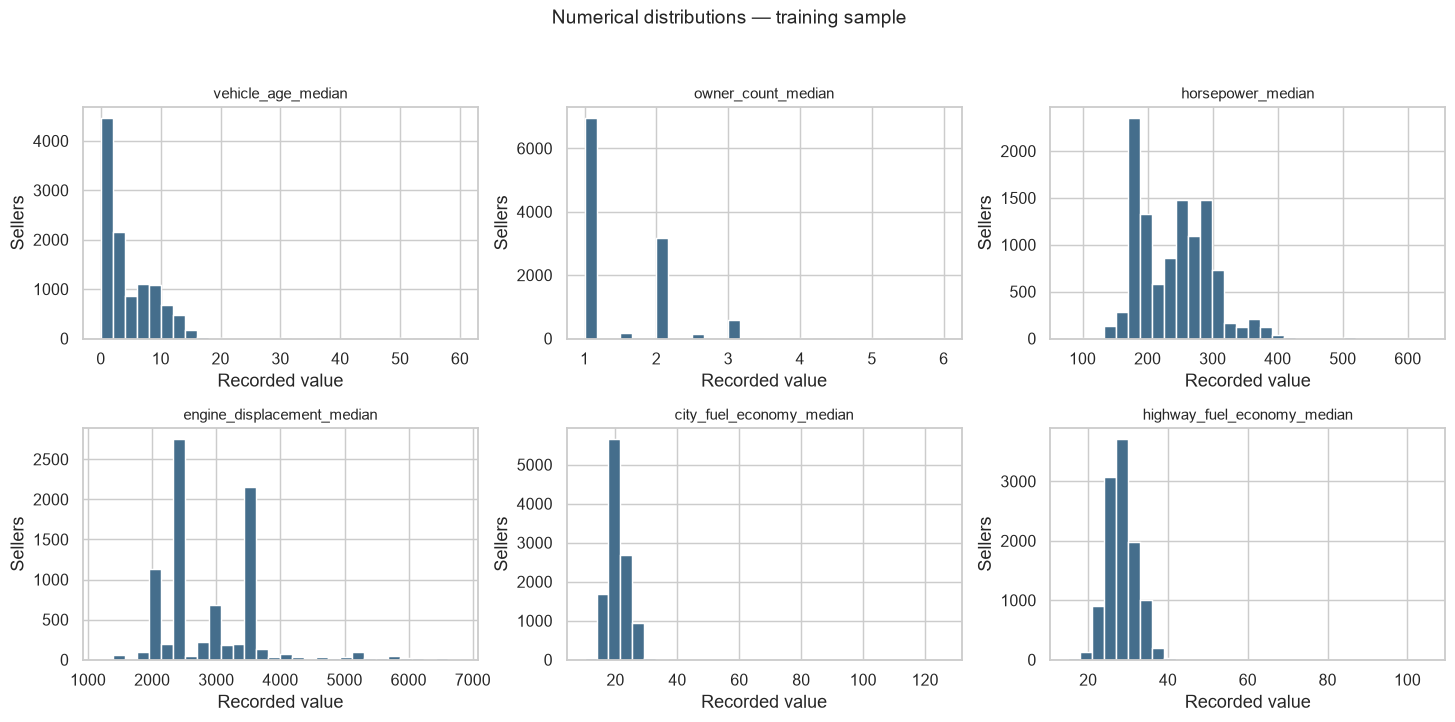

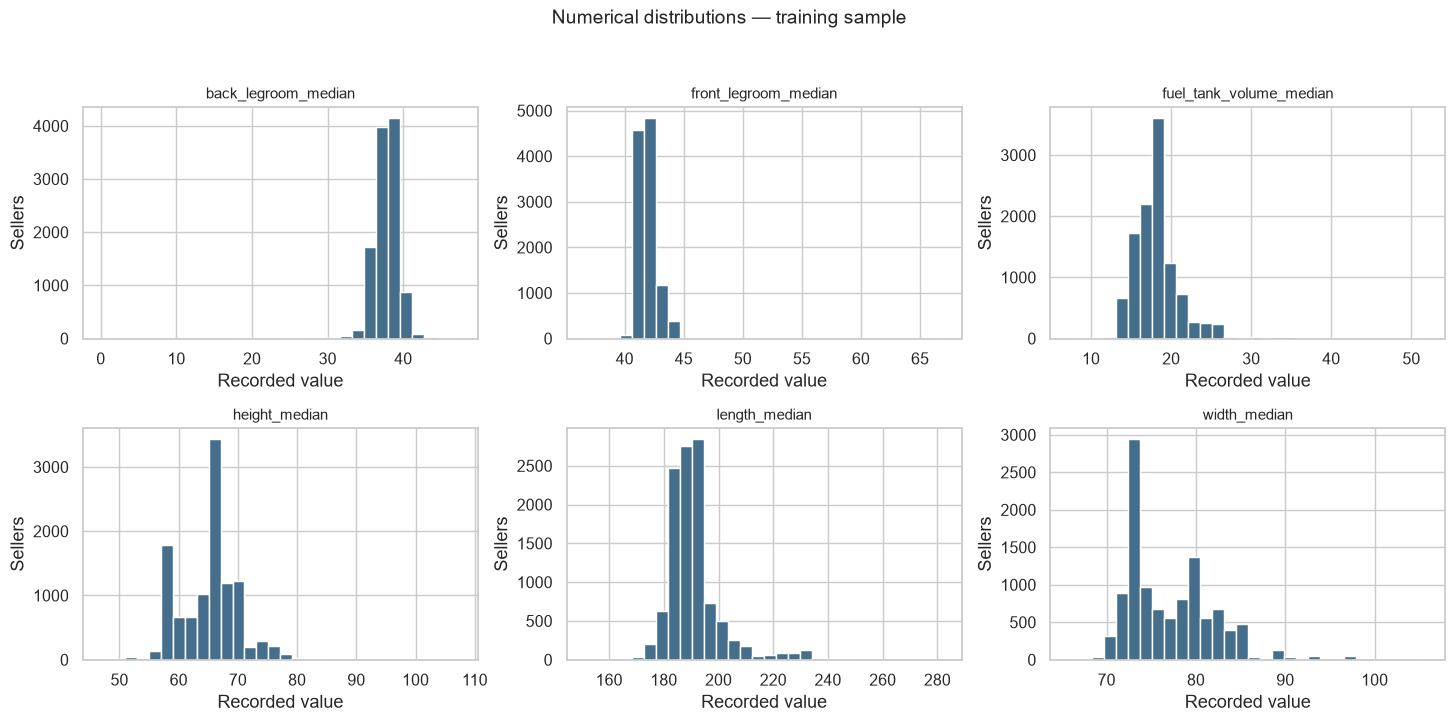

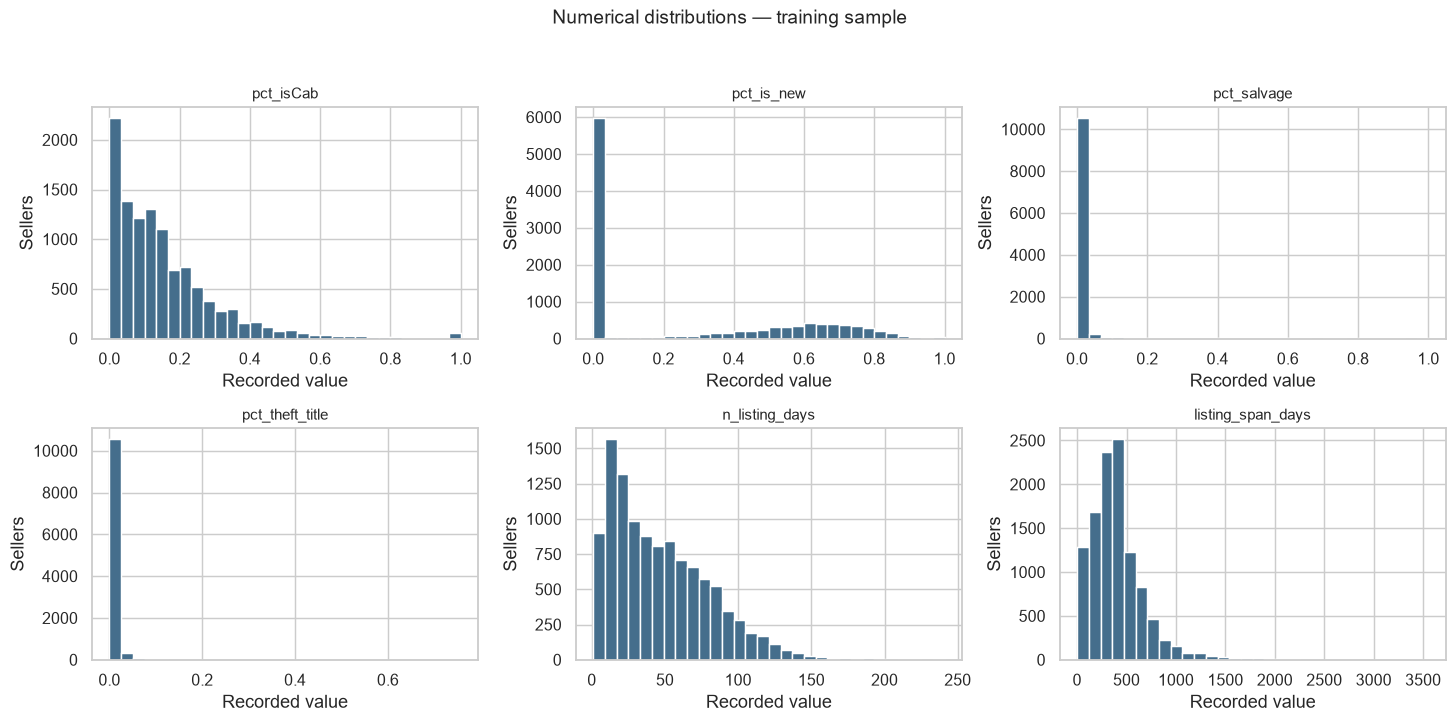

In [11]:
for start in range(0, len(numeric_columns), 6):
    columns = numeric_columns[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 7))
    for ax, column in zip(axes.ravel(), columns):
        ax.hist(train_df[column].dropna(), bins=30, color="#456e8c", edgecolor="white")
        ax.set_title(column, fontsize=10)
        ax.set_xlabel("Recorded value")
        ax.set_ylabel("Sellers")
    for ax in axes.ravel()[len(columns):]:
        ax.set_visible(False)
    fig.suptitle("Numerical distributions — training sample", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

Listing counts, prices, advertised savings and time on the market have long right tails. Their means and medians differ, so the median and quartiles are useful alongside the mean and standard deviation. The raw histograms retain the full recorded range; extreme values can compress the central part of a panel.

The salvage and theft-title proportions are concentrated at zero. These are shares, not binary seller-level flags. Median model year and age at listing describe related aspects of the inventory, which will be examined in 1.5. The distributions do not establish whether rare values are recording errors.

### 1.2.3 Categorical distributions

,observed_categories,missing,literal_unknown
dominant_body_type,9,0,0
dominant_fuel_type,6,0,0
dominant_transmission,4,0,5
dominant_wheel_system,5,8379,0
dominant_listing_color,10,0,1209
franchise_status,2,0,0
new_used_profile,3,0,0


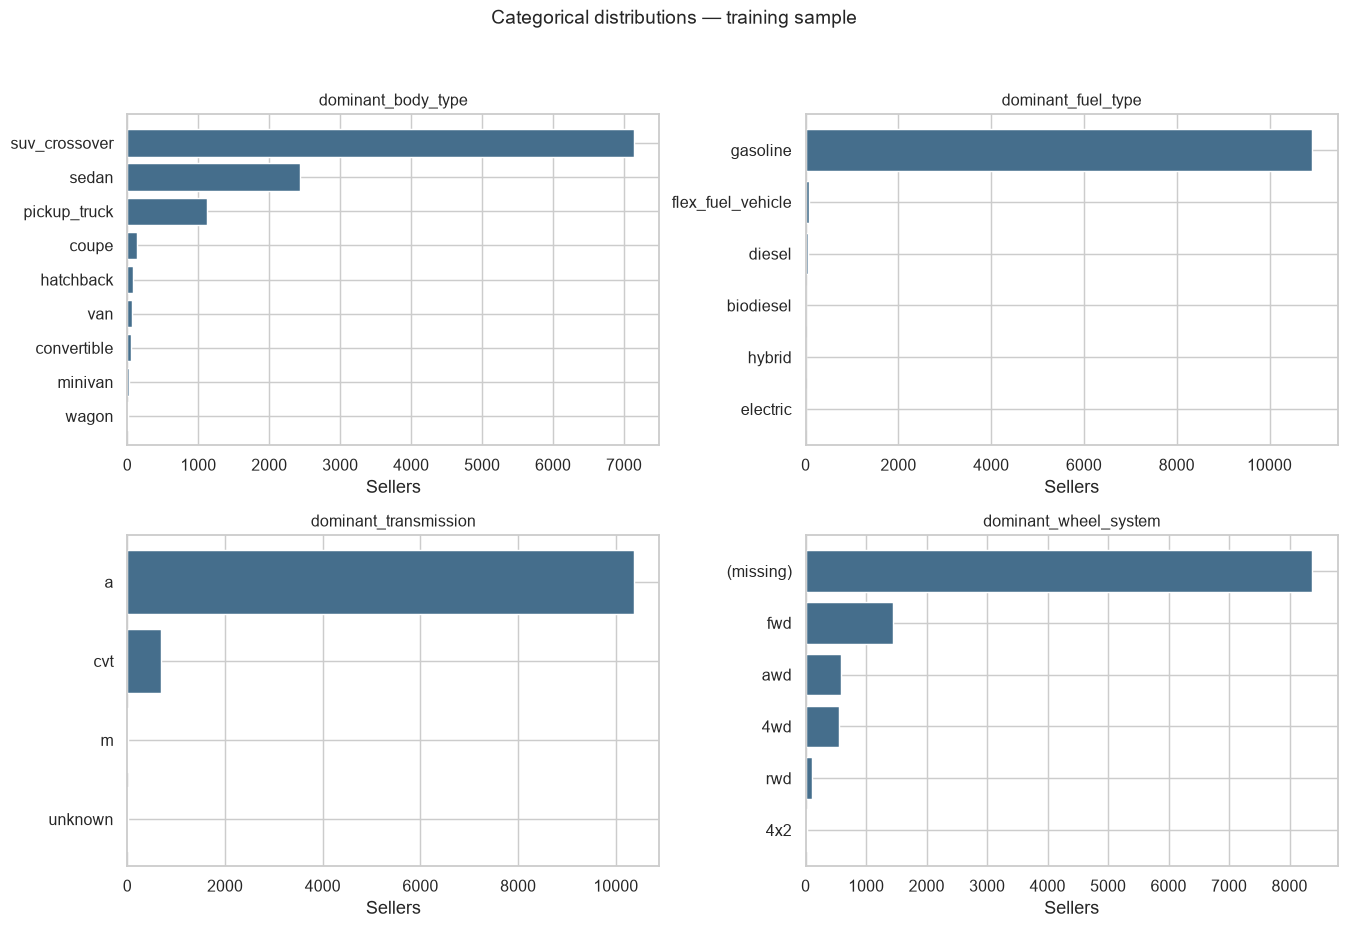

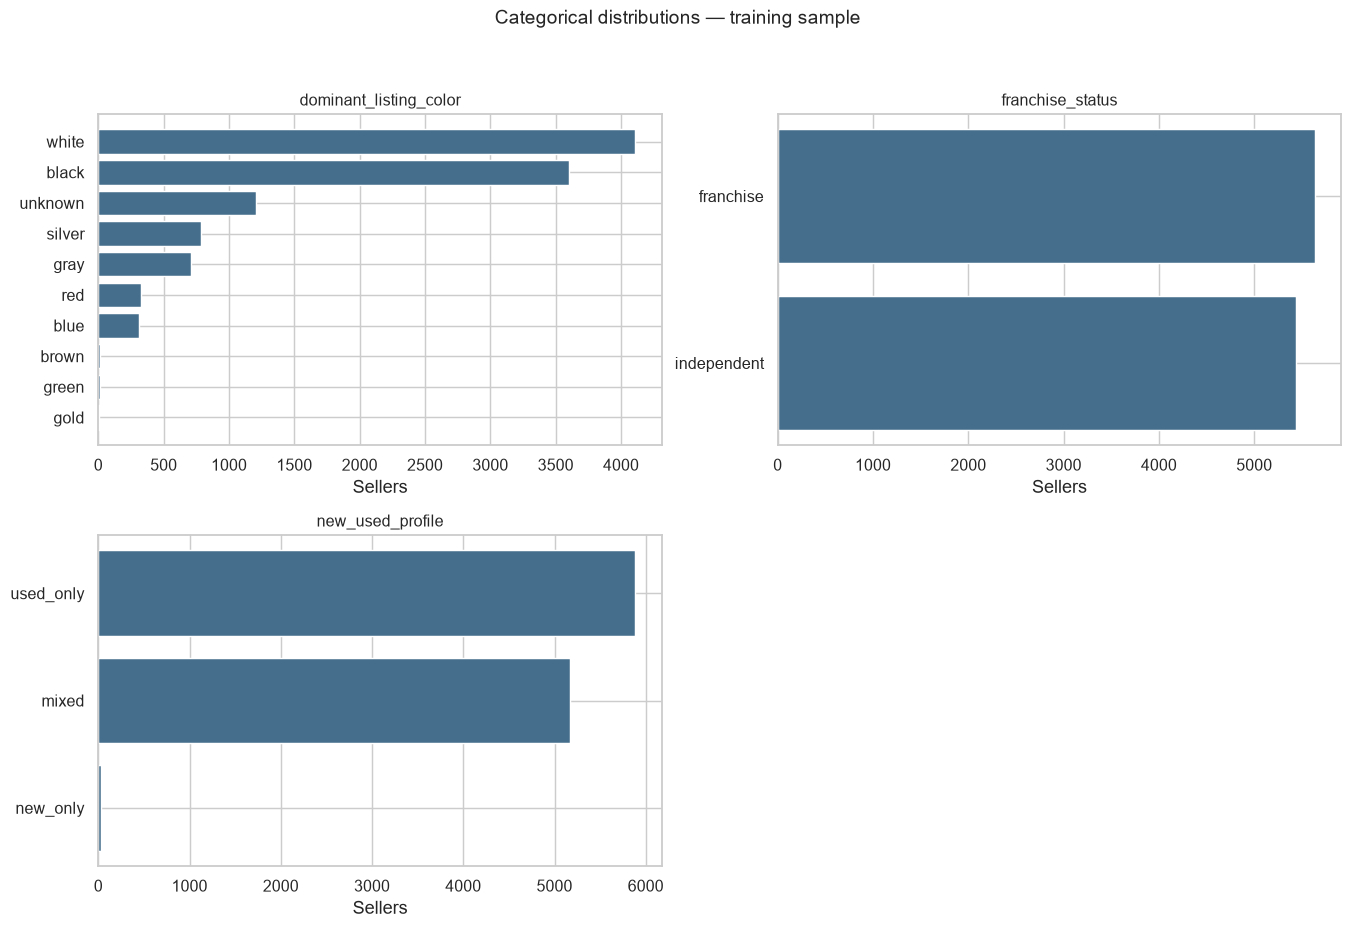

In [12]:
categorical_summary = pd.DataFrame({
    "observed_categories": train_df[categorical_columns].nunique(),
    "missing": train_df[categorical_columns].isna().sum(),
    "literal_unknown": train_df[categorical_columns].eq("unknown").sum()
})
display(categorical_summary)

for start in range(0, len(categorical_columns), 4):
    columns = categorical_columns[start:start + 4]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for ax, column in zip(axes.ravel(), columns):
        values = train_df[column].fillna("(missing)").value_counts().sort_values()
        ax.barh(values.index, values.values, color="#456e8c")
        ax.set_title(column, fontsize=11)
        ax.set_xlabel("Sellers")
    for ax in axes.ravel()[len(columns):]:
        ax.set_visible(False)
    fig.suptitle("Categorical distributions — training sample", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

Gasoline and transmission code a dominate their respective columns; several other categories are rare. Most sellers have SUV/crossover as their dominant body type. Franchise status is much more evenly distributed.

The wheel-system column is mostly missing. The literal unknown labels, especially for listing color, are reported separately from empty entries: their meaning is not automatically equated with a missing CSV value. No categories are merged based on automotive assumptions.

Line plots are not used here because there is no sequence of dated observations per seller. Connecting arbitrary seller rows would suggest an order that the data do not provide.

## 1.3 Assessment of data quality

### 1.3.1 Missing data and duplicate records

Counts below refer to the training sample unless explicitly stated. A missing-value percentage is based on all training records, not just the non-missing observations.

,missing_count,missing_percent
dominant_wheel_system,8379,75.66
engine_displacement_median,2711,24.48
owner_count_median,29,0.26
pct_salvage,22,0.20
pct_isCab,22,0.20
pct_theft_title,22,0.20
back_legroom_median,15,0.14
city_fuel_economy_median,13,0.12
highway_fuel_economy_median,13,0.12
fuel_tank_volume_median,5,0.05


,count
full_rows_duplicated_in_source,0
seller_ids_duplicated_in_source,0
missing_seller_ids_in_source,0


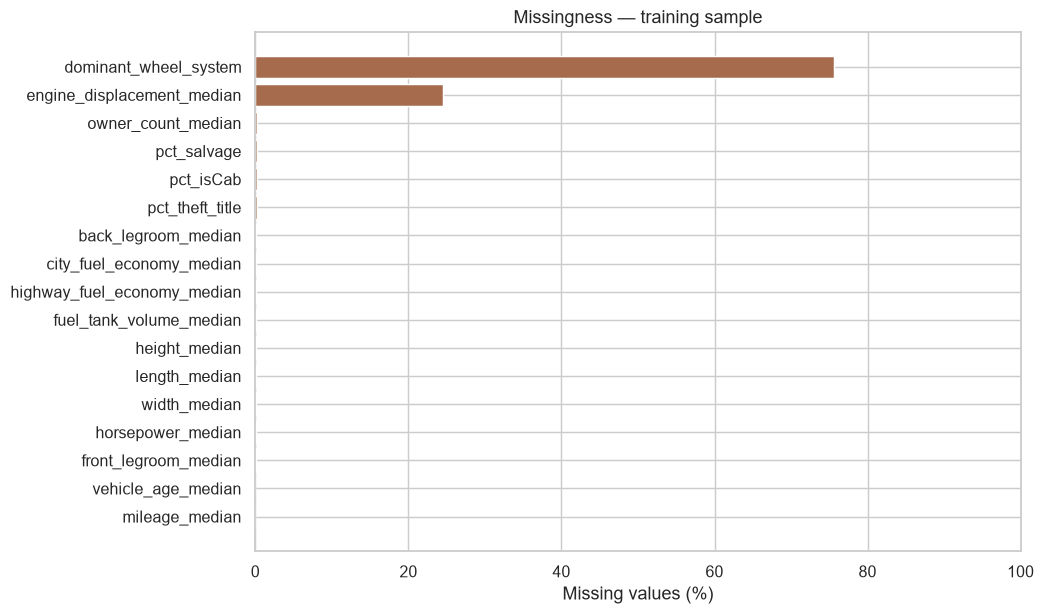

In [13]:
missing_summary = train_df.isna().sum().to_frame("missing_count")
missing_summary["missing_percent"] = missing_summary["missing_count"] / len(train_df) * 100
missing_summary = missing_summary.sort_values("missing_count", ascending=False)
display(missing_summary.loc[missing_summary["missing_count"] > 0].round(2))

duplicate_summary = pd.Series({
    "full_rows_duplicated_in_source": int(df.duplicated().sum()),
    "seller_ids_duplicated_in_source": int(df[ID_COLUMN].duplicated().sum()),
    "missing_seller_ids_in_source": int(df[ID_COLUMN].isna().sum())
}, name="count")
display(duplicate_summary.to_frame())

fig, ax = plt.subplots(figsize=(10, 6))
nonzero_missing = missing_summary.loc[missing_summary["missing_count"] > 0]
ax.barh(nonzero_missing.index[::-1], nonzero_missing["missing_percent"].iloc[::-1], color="#a66b4d")
ax.set(xlabel="Missing values (%)", title="Missingness — training sample")
ax.set_xlim(0, 100)
fig.tight_layout()
plt.show()

About three quarters of wheel-system entries and one quarter of engine-displacement entries are missing. Missingness in the other numerical columns is much smaller. Dropping every incomplete row would discard many sellers, so row-wise complete-case deletion is not used.

For the baseline feature set, we will exclude wheel system because imputation would determine most of its values. The 50% missingness threshold below is a stated project choice, not a universal rule. Engine displacement is retained with median imputation and a separate missingness indicator. That indicator records availability; it does not assert why the value is missing. Missing numerical values in the other retained columns will also be filled with training medians.

No duplicate source rows or seller identifiers were found, so no deduplication is applied.

### 1.3.2 General consistency checks

In [14]:
proportion_columns = ["pct_isCab", "pct_is_new", "pct_salvage", "pct_theft_title"]
count_columns = ["n_listings", "n_listing_days", "listing_span_days"]

quality_checks = {
    "infinite_numeric_values": int(np.isinf(train_df[numeric_columns]).sum().sum()),
    "negative_numeric_values": int(train_df[numeric_columns].lt(0).sum().sum()),
    "nonpositive_model_years": int(train_df["year_median"].le(0).sum()),
    "fractional_listing_counts_or_days": int(
        train_df[count_columns].mod(1).ne(0).where(train_df[count_columns].notna(), False).sum().sum()
    ),
    "proportions_outside_0_1": int(
        (train_df[proportion_columns].lt(0) | train_df[proportion_columns].gt(1)).sum().sum()
    ),
    "distinct_days_exceed_listing_count": int(
        train_df["n_listing_days"].gt(train_df["n_listings"]).sum()
    ),
    "distinct_days_exceed_inclusive_span": int(
        train_df["n_listing_days"].gt(train_df["listing_span_days"] + 1).sum()
    )
}

documented_categories = {
    "franchise_status": ["franchise", "independent", "mixed", "unknown"],
    "new_used_profile": ["new_only", "used_only", "mixed", "unknown"],
    TARGET: RATING_ORDER
}
for column, allowed in documented_categories.items():
    invalid = train_df[column].notna() & ~train_df[column].isin(allowed)
    quality_checks["undocumented_" + column] = int(invalid.sum())

quality_table = pd.Series(quality_checks, name="violations").to_frame()
display(quality_table)
assert quality_table["violations"].eq(0).all(), "Review rule violations before preparing features." 

,violations
infinite_numeric_values,0
negative_numeric_values,0
nonpositive_model_years,0
fractional_listing_counts_or_days,0
proportions_outside_0_1,0
distinct_days_exceed_listing_count,0
distinct_days_exceed_inclusive_span,0
undocumented_franchise_status,0
undocumented_new_used_profile,0
undocumented_seller_rating_class,0


The checks return no violations in the training sample. Counts and elapsed days should be whole and non-negative; a proportion should be between 0 and 1. The number of distinct observed days cannot exceed the number of listings or the inclusive date span. These rules follow from the supplied definitions.

This is not a certificate that all records are correct. No upper bounds for engine characteristics, prices or vehicle dimensions are invented. Zero rear legroom and extreme fuel-economy values deserve review, but their meaning cannot be resolved from the available description. They are retained, as are fractional medians. Negative advertised savings would also require clarification if present; none are observed here.

### 1.3.3 Outliers and noise

In [15]:
q1 = train_df[numeric_columns].quantile(0.25)
q3 = train_df[numeric_columns].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outside_fences = (
    train_df[numeric_columns].lt(lower_fence)
    | train_df[numeric_columns].gt(upper_fence)
)
outlier_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "lower_fence": lower_fence,
    "upper_fence": upper_fence,
    "flagged_count": outside_fences.sum(),
    "flagged_percent_of_observed": outside_fences.sum() / train_df[numeric_columns].notna().sum() * 100
})
display(outlier_summary.sort_values("flagged_count", ascending=False).round(3))

,Q1,Q3,IQR,lower_fence,upper_fence,flagged_count,flagged_percent_of_observed
pct_theft_title,0.000,0.000,0.000,0.000,0.000,1699,15.373
pct_salvage,0.000,0.000,0.000,0.000,0.000,985,8.912
daysonmarket_median,26.000,51.000,25.000,-11.500,88.500,885,7.992
length_median,184.600,192.700,8.100,172.450,204.850,746,6.739
fuel_tank_volume_median,16.400,19.200,2.800,12.200,23.400,648,5.854
pct_isCab,0.048,0.214,0.167,-0.202,0.464,513,4.642
n_listings,25.000,168.000,143.000,-189.500,382.500,505,4.560
listing_span_days,224.000,511.000,287.000,-206.500,941.500,493,4.452
front_legroom_median,41.300,42.200,0.900,39.950,43.550,431,3.893
engine_displacement_median,2400.000,3500.000,1100.000,750.000,5150.000,252,3.013


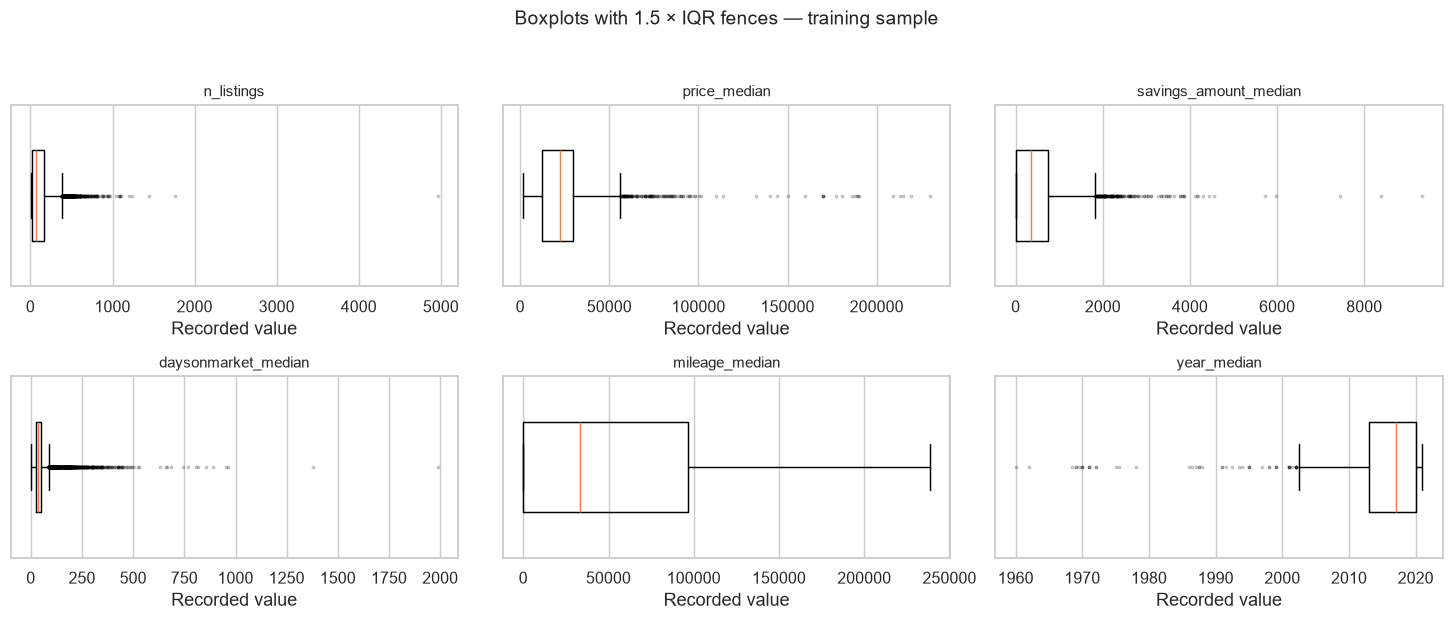

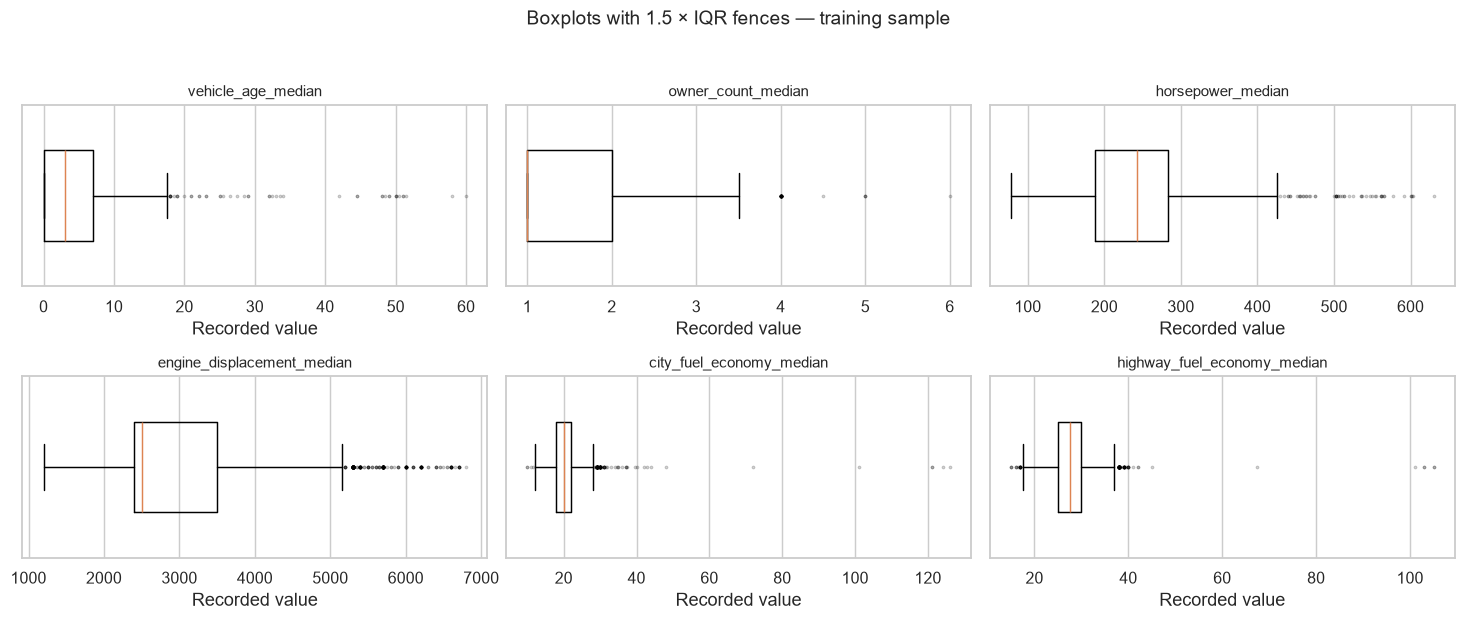

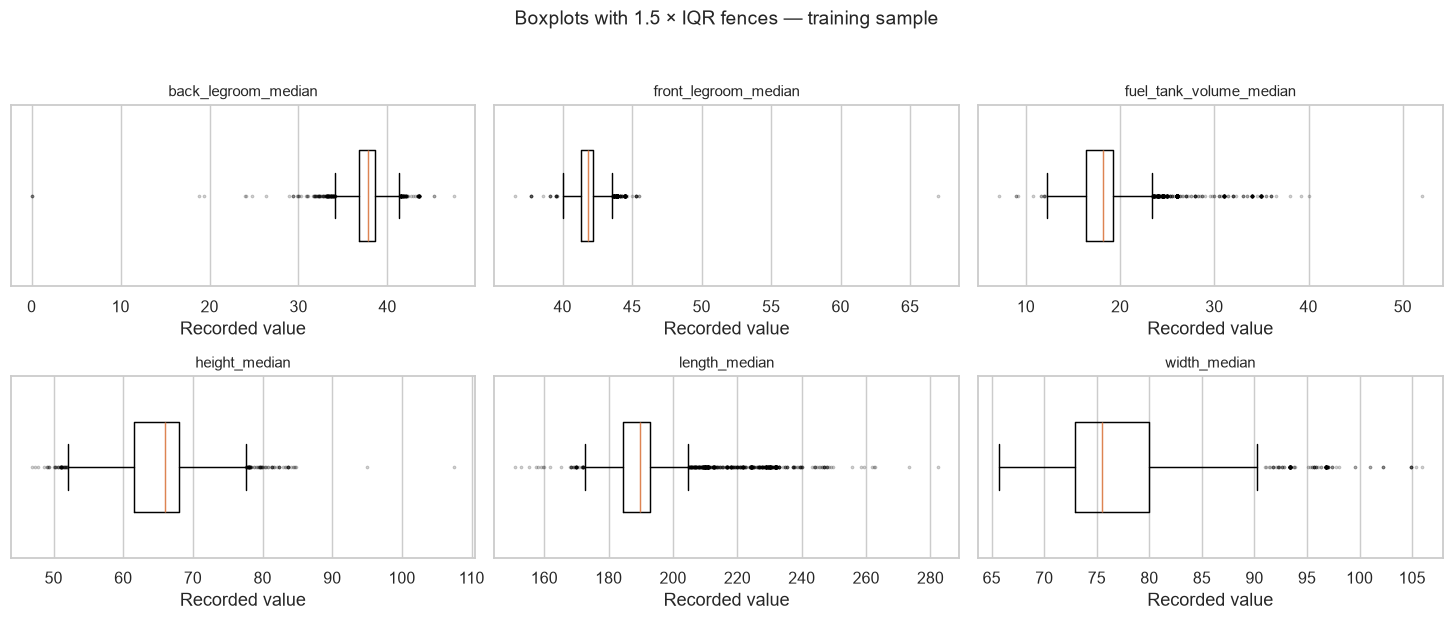

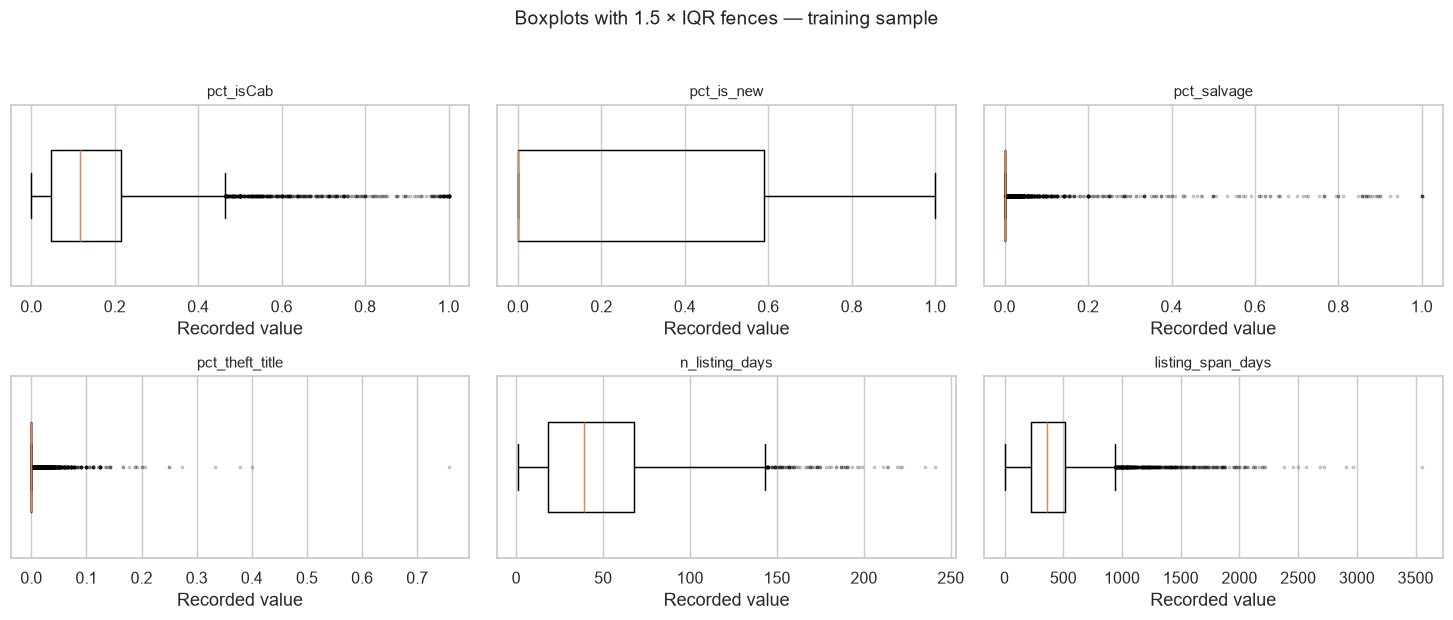

In [16]:
for start in range(0, len(numeric_columns), 6):
    columns = numeric_columns[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(14, 6))
    for ax, column in zip(axes.ravel(), columns):
        ax.boxplot(
            train_df[column].dropna(), orientation="horizontal", widths=0.5,
            flierprops={"marker": ".", "markersize": 3, "alpha": 0.25}
        )
        ax.set_title(column, fontsize=10)
        ax.set_xlabel("Recorded value")
        ax.set_yticks([])
    for ax in axes.ravel()[len(columns):]:
        ax.set_visible(False)
    fig.suptitle("Boxplots with 1.5 × IQR fences — training sample", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    plt.show()

The IQR rule flags observations for inspection; it does not identify errors by itself. In columns concentrated at zero, Q1 and Q3 can both be zero. The resulting zero-width fence then flags every positive value, including valid nonzero proportions. Deleting all flagged rows would change the population without enough justification.

No blanket trimming, capping or rounding is applied. Instead, selected long-tailed variables are considered for a log transformation in 1.4. Rare categories and extreme values remain possible limitations for later distance-based analysis.

## 1.4 Data transformation

### 1.4.1 Comparing raw and logarithmic values

We consider log1p for non-negative inventory size, price, savings and listing-duration variables with wide ranges. It equals log(1 + x), so recorded zeros remain defined. We do not log calendar years or bounded proportions.

The rule for this baseline is explicit: among the five candidates below, use log1p only if the training skewness is above 1 and the transformed absolute skewness is below 1. This is a descriptive heuristic, not a claim that a normally distributed feature is required or that the choice maximizes model performance.

,raw_skewness,log1p_skewness,use_log1p
n_listings,5.878,-0.132,True
price_median,3.335,-0.438,True
savings_amount_median,2.572,-0.410,True
daysonmarket_median,9.359,0.472,True
listing_span_days,2.182,-1.233,False


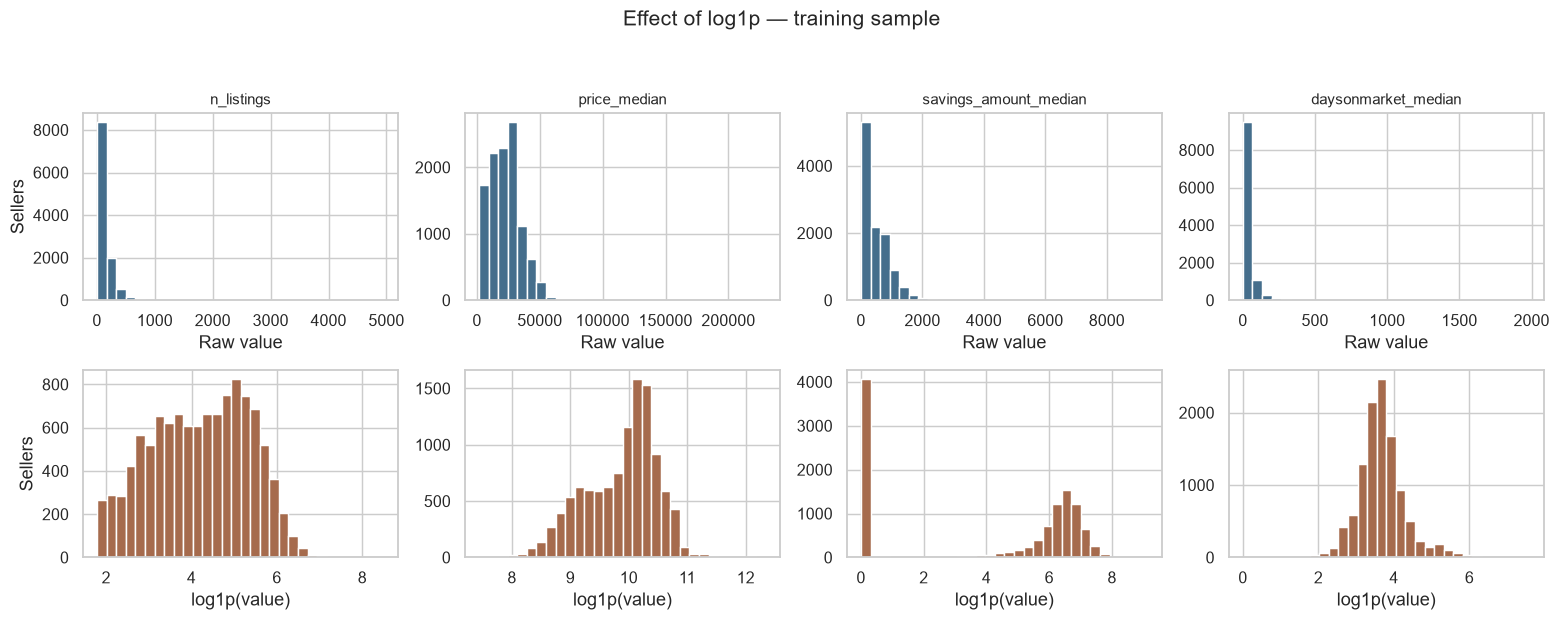

Log-transformed variables: ['n_listings', 'price_median', 'savings_amount_median', 'daysonmarket_median']


In [17]:
log_candidates = [
    "n_listings", "price_median", "savings_amount_median",
    "daysonmarket_median", "listing_span_days"
]
log_comparison = pd.DataFrame({
    "raw_skewness": train_df[log_candidates].skew(),
    "log1p_skewness": np.log1p(train_df[log_candidates]).skew()
})
log_comparison["use_log1p"] = (
    log_comparison["raw_skewness"].gt(1)
    & log_comparison["log1p_skewness"].abs().lt(1)
)
log_columns = log_comparison.index[log_comparison["use_log1p"]].tolist()
display(log_comparison.round(3))
print("Log-transformed variables:", log_columns)

fig, axes = plt.subplots(2, len(log_columns), figsize=(15, 6))
for i, column in enumerate(log_columns):
    values = train_df[column].dropna()
    axes[0, i].hist(values, bins=30, color="#456e8c")
    axes[0, i].set_title(column, fontsize=10)
    axes[0, i].set_xlabel("Raw value")
    axes[1, i].hist(np.log1p(values), bins=30, color="#a66b4d")
    axes[1, i].set_xlabel("log1p(value)")
axes[0, 0].set_ylabel("Sellers")
axes[1, 0].set_ylabel("Sellers")
fig.suptitle("Effect of log1p — training sample")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

The rule selects n_listings, price_median, savings_amount_median and daysonmarket_median. Their transformed skewness lies between -1 and 1. For listing_span_days, log1p produces a pronounced left tail (skewness about -1.23), so it remains on its original scale before standardization.

The transformation reduces the influence of absolute scale differences and compresses large values without removing records. It changes distances and linear relationships, so it is a modelling choice that may need revisiting for a particular algorithm.

### 1.4.2 Scaling and encoding choices

In [18]:
scaling_input = train_df[["price_median"]].copy()
scaling_input["price_median"] = np.log1p(scaling_input["price_median"])

standard_example = StandardScaler().fit_transform(scaling_input)
minmax_example = MinMaxScaler().fit_transform(scaling_input)

scaling_comparison = pd.DataFrame({
    "log1p_price": scaling_input["price_median"].to_numpy(),
    "standardized": standard_example.ravel(),
    "minmax": minmax_example.ravel()
}, index=train_df.index)
display(scaling_comparison.describe().round(3))
display(scaling_comparison.head().round(3))

,log1p_price,standardized,minmax
count,11074.000,11074.000,11074.000
mean,9.875,-0.000,0.496
std,0.621,1.000,0.127
min,7.438,-3.924,0.000
25%,9.433,-0.711,0.407
50%,10.020,0.235,0.526
75%,10.305,0.693,0.584
max,12.345,3.980,1.000


,log1p_price,standardized,minmax
5664,10.187,0.504,0.560
4046,8.517,-2.186,0.220
3243,9.903,0.046,0.502
5427,9.873,-0.003,0.496
7483,10.713,1.351,0.667


Both scalers are fitted here on the training sample only. Standardization uses (x - training mean) / training standard deviation. Min-max scaling uses the training minimum and maximum. StandardScaler uses the population standard deviation, whereas pandas describe reports the sample standard deviation, so its displayed standard deviation can differ slightly from 1.

We use standardization for the continuous/numerical feature blocks as a baseline for later distance-based methods. Min-max scaling is shown for comparison; it can compress most values when a few extremes determine the range. Standardization is also sensitive to extremes, so the decision is not a substitute for checking the effect of outliers in a later algorithm.

Nominal categories will be one-hot encoded, without assigning arbitrary numerical order. Their indicator columns and the engine-missingness flag stay at 0/1 rather than being standardized. This avoids giving very rare indicators large magnitudes, but the relative weight of numerical and categorical blocks will still matter for clustering.

All fitted imputation, scaling and category-encoding steps are collected in one pipeline below, after the feature decisions in 1.5. This avoids maintaining two different prepared datasets.

## 1.5 Pairwise correlation and variable elimination

### 1.5.1 Correlations on observed numerical values

The identifier and target are excluded. Pearson correlation measures linear association; Spearman correlation measures rank association and provides a useful comparison in the presence of skewness. Both calculations use pairwise complete observations. The number of complete pairs is reported for the highly correlated pairs rather than treating all coefficients as equally well supported.

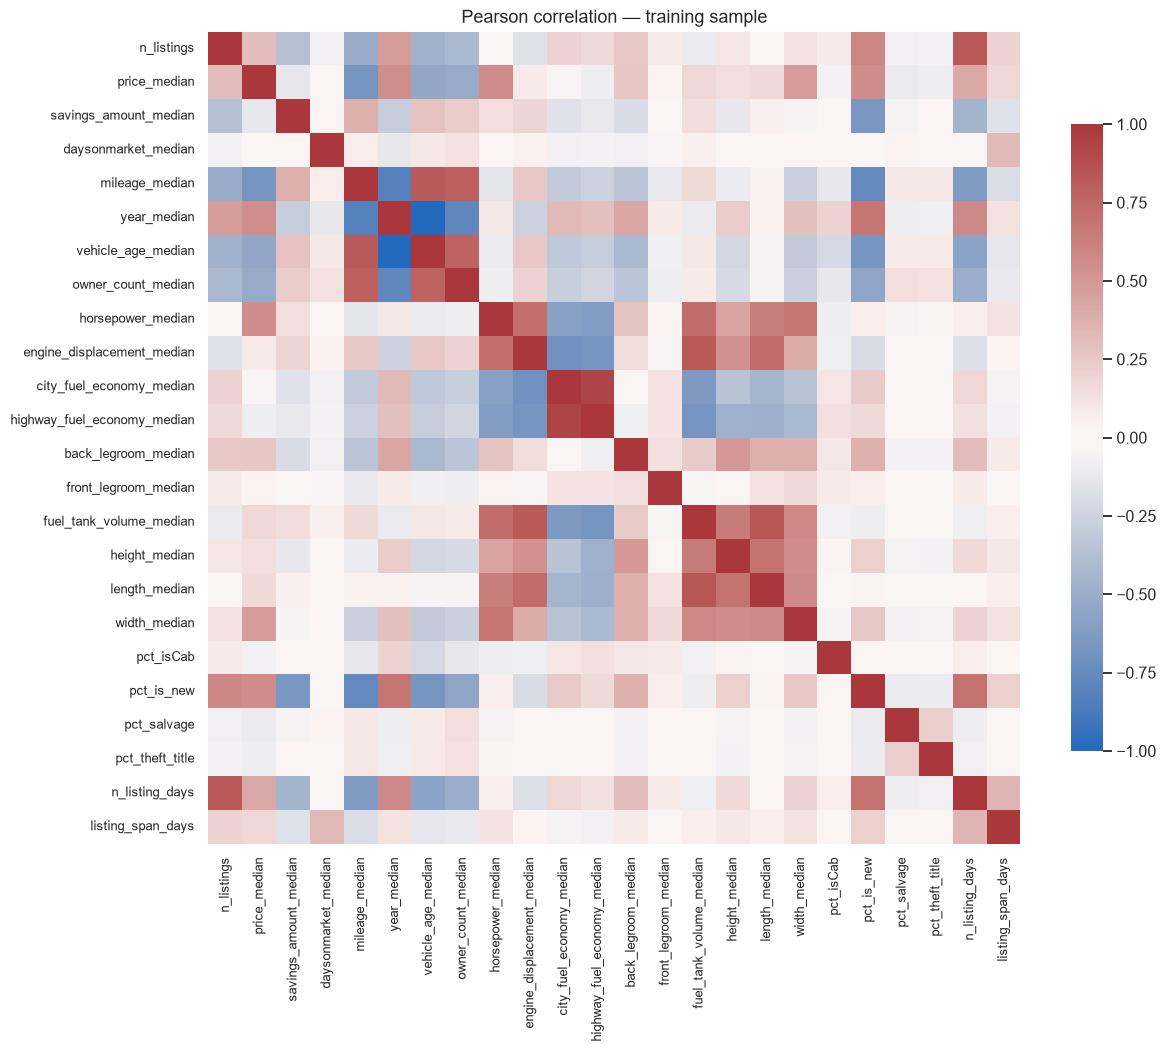

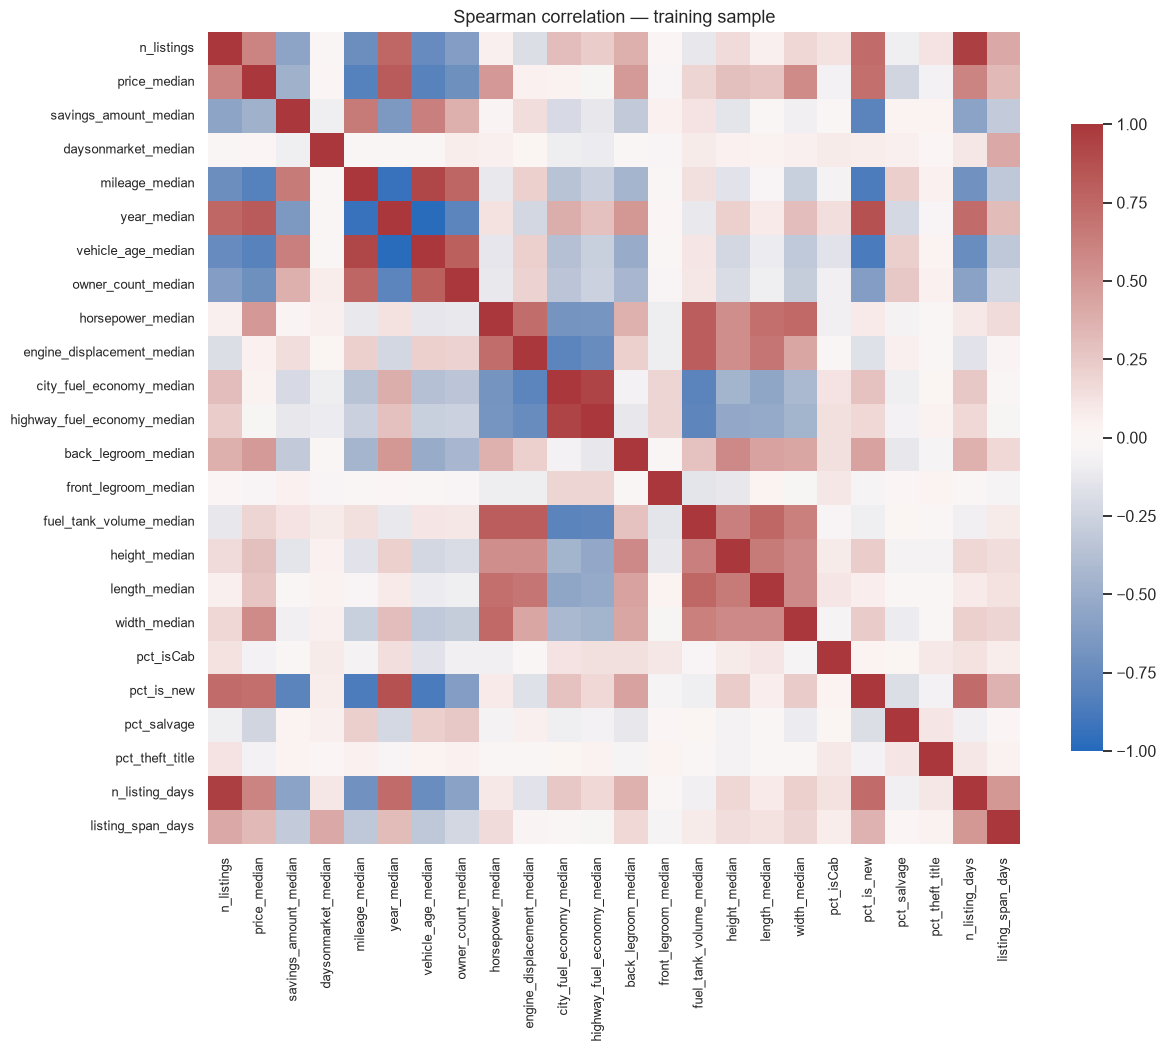

,first,second,pearson,spearman,complete_pairs
0,year_median,vehicle_age_median,-0.9963,-0.9838,11073
1,city_fuel_economy_median,highway_fuel_economy_median,0.9347,0.9364,11061


In [19]:
pearson = train_df[numeric_columns].corr(method="pearson")
spearman = train_df[numeric_columns].corr(method="spearman")
for matrix, title in [(pearson, "Pearson"), (spearman, "Spearman")]:
    fig, ax = plt.subplots(figsize=(12, 11))
    sns.heatmap(
        matrix, ax=ax, vmin=-1, vmax=1, center=0, cmap="vlag",
        square=True, cbar_kws={"shrink": 0.65}
    )
    ax.set_title(title + " correlation — training sample")
    ax.tick_params(axis="both", labelsize=9)
    fig.tight_layout()
    plt.show()

high_pairs = []
for i, first in enumerate(numeric_columns):
    for second in numeric_columns[i + 1:]:
        coefficient = pearson.loc[first, second]
        if abs(coefficient) >= 0.90:
            high_pairs.append({
                "first": first, "second": second,
                "pearson": coefficient,
                "spearman": spearman.loc[first, second],
                "complete_pairs": len(train_df[[first, second]].dropna())
            })
high_correlation_pairs = pd.DataFrame(high_pairs)
display(high_correlation_pairs.round(4))

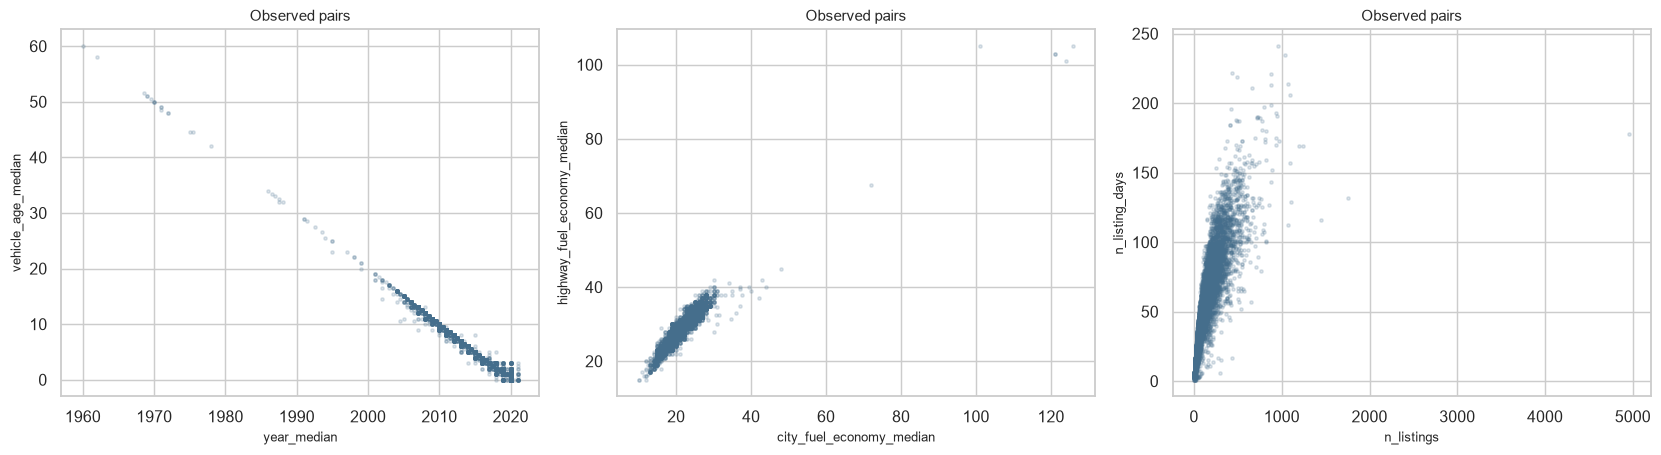

In [20]:
scatter_pairs = [
    ("year_median", "vehicle_age_median"),
    ("city_fuel_economy_median", "highway_fuel_economy_median"),
    ("n_listings", "n_listing_days")
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (first, second) in zip(axes, scatter_pairs):
    values = train_df[[first, second]].dropna()
    ax.scatter(values[first], values[second], s=5, alpha=0.18, color="#456e8c")
    ax.set_xlabel(first, fontsize=9)
    ax.set_ylabel(second, fontsize=9)
    ax.set_title("Observed pairs", fontsize=10)
fig.tight_layout()
plt.show()

Median model year and age at listing are almost perfectly negatively correlated (Pearson about -0.996). We retain age at listing for its direct interpretation and remove median year from the baseline representation. This does not assume an exact equality between the two aggregates.

City and highway fuel economy are also strongly positively correlated (Pearson about 0.935). We retain highway fuel economy and remove city fuel economy to reduce repeated weighting of the same broad characteristic. The 0.90 threshold identifies candidates for review, not an automatic rule to drop every correlated variable. This selection is a baseline choice and does not establish that city fuel economy is useless for prediction.

Listing count and distinct listing days are related but describe different aspects of activity. Both are retained. Correlation is not evidence of causation.

### 1.5.2 Checking an explicitly derived categorical profile

In [21]:
profile_from_share = pd.Series(
    np.where(
        train_df["pct_is_new"].eq(0), "used_only",
        np.where(train_df["pct_is_new"].eq(1), "new_only", "mixed")
    ),
    index=train_df.index,
    name="profile_from_pct_is_new"
)
profile_mismatches = int(train_df["new_used_profile"].ne(profile_from_share).sum())
display(pd.crosstab(train_df["new_used_profile"], profile_from_share))
print("Profile disagreements in training data:", profile_mismatches)

profile_from_pct_is_new,mixed,new_only,used_only
new_used_profile,,,
mixed,5166,0,0
new_only,0,24,0
used_only,0,0,5884


Profile disagreements in training data: 0


In the training sample, new_used_profile exactly reproduces the zero/intermediate/one grouping of pct_is_new. We retain the numerical share and omit the categorical profile to avoid representing the same inventory information twice. This conclusion is checked against the data, rather than assumed solely from the column names.

In [22]:
missing_fraction = train_df.isna().mean()
high_missing_columns = [
    c for c in numeric_columns + categorical_columns
    if missing_fraction[c] > 0.50
]
constant_columns = [
    c for c in numeric_columns + categorical_columns
    if train_df[c].nunique(dropna=True) <= 1
]
correlation_drops = ["year_median", "city_fuel_economy_median"]
derived_drops = ["new_used_profile"] if profile_mismatches == 0 else []

excluded_columns = list(dict.fromkeys(
    high_missing_columns + constant_columns + correlation_drops + derived_drops
))
selected_numeric = [c for c in numeric_columns if c not in excluded_columns]
selected_categorical = [c for c in categorical_columns if c not in excluded_columns]
decision_table = pd.DataFrame([
    (ID_COLUMN, "Exclude from features", "Identifier, retained separately for traceability"),
    (TARGET, "Keep only as target", "Never included in the feature matrix"),
    ("dominant_wheel_system", "Exclude from baseline", "More than 50% missing in training"),
    ("engine_displacement_median", "Retain", "Median imputation plus an unscaled missingness flag"),
    ("year_median", "Exclude from baseline", "Near-redundant with age at listing"),
    ("city_fuel_economy_median", "Exclude from baseline", "Strong association with highway fuel economy"),
    ("new_used_profile", "Exclude if exact grouping", "Training check against pct_is_new")
], columns=["variable", "decision", "reason"])
display(decision_table)
print("Columns above the missingness threshold:", high_missing_columns)
print("Constant input columns:", constant_columns)
print("Retained numerical variables:", len(selected_numeric))
print("Retained categorical variables:", len(selected_categorical))

,variable,decision,reason
0,sp_id,Exclude from features,"Identifier, retained separately for traceability"
1,seller_rating_class,Keep only as target,Never included in the feature matrix
2,dominant_wheel_system,Exclude from baseline,More than 50% missing in training
3,engine_displacement_median,Retain,Median imputation plus an unscaled missingness flag
4,year_median,Exclude from baseline,Near-redundant with age at listing
5,city_fuel_economy_median,Exclude from baseline,Strong association with highway fuel economy
6,new_used_profile,Exclude if exact grouping,Training check against pct_is_new


Columns above the missingness threshold: ['dominant_wheel_system']
Constant input columns: []
Retained numerical variables: 22
Retained categorical variables: 5


### 1.5.3 Reproducible preparation pipeline

Numerical missing values are filled with training medians. Selected long-tailed variables then receive log1p, and all numerical variables are standardized. Remaining nominal missing values receive a separate missing label before one-hot encoding; the existing unknown label is preserved. An unseen test category is encoded as zeros in its category block, so it does not cause an error or change the learned vocabulary.

The engine-displacement missingness flag is constructed before imputation and is not scaled. The same deterministic feature-construction function is used for both subsets. We retain full one-hot blocks at this stage; a later unregularized linear model may need a different encoding to avoid dummy-variable collinearity.

In [23]:
def make_feature_frame(frame):
    features = frame[selected_numeric + selected_categorical].copy()
    for column in selected_categorical:
        features[column] = features[column].astype(object).where(features[column].notna(), np.nan)
    features["engine_displacement_missing"] = (
        frame["engine_displacement_median"].isna().astype(int)
    )
    return features

X_train = make_feature_frame(train_df)
X_test = make_feature_frame(test_df)
y_train = train_df[TARGET].copy()
y_test = test_df[TARGET].copy()
train_seller_ids = train_df[ID_COLUMN].copy()
test_seller_ids = test_df[ID_COLUMN].copy()

selected_log_columns = [c for c in log_columns if c in selected_numeric]
plain_numeric_columns = [c for c in selected_numeric if c not in selected_log_columns]

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="__missing__")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("log", log_pipeline, selected_log_columns),
    ("numeric", numeric_pipeline, plain_numeric_columns),
    ("category", categorical_pipeline, selected_categorical),
    ("missing_flag", "passthrough", ["engine_displacement_missing"])
])

train_values = preprocessor.fit_transform(X_train)
test_values = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_prepared = pd.DataFrame(train_values, index=X_train.index, columns=feature_names)
X_test_prepared = pd.DataFrame(test_values, index=X_test.index, columns=feature_names)

print("Prepared training shape:", X_train_prepared.shape)
print("Prepared test shape:", X_test_prepared.shape)
display(X_train_prepared.iloc[:5, :8].round(3))

,log__n_listings,log__price_median,log__savings_amount_median,log__daysonmarket_median,numeric__mileage_median,numeric__vehicle_age_median,numeric__owner_count_median,numeric__horsepower_median
5664,1.782,0.504,-1.271,2.719,-0.991,-0.881,0.927,-0.890
4046,-0.146,-2.186,0.668,0.416,1.817,2.151,0.927,-0.803
3243,1.503,0.046,0.666,0.385,-0.421,-0.448,-0.695,-1.030
5427,1.407,-0.003,0.306,0.115,-0.369,-0.231,-0.695,-0.986
7483,0.760,1.351,-1.271,2.016,-0.991,-0.881,-0.695,0.944


Prepared training shape: (11074, 54)
Prepared test shape: (2769, 54)


In [24]:
unseen_category_counts = {}
for column in selected_categorical:
    known = set(X_train[column].dropna().unique())
    unseen = X_test[column].notna() & ~X_test[column].isin(known)
    unseen_category_counts[column] = int(unseen.sum())
display(pd.Series(unseen_category_counts, name="test_rows_with_unseen_category").to_frame())

imputation_values = {}
for block, columns in [("log", selected_log_columns), ("numeric", plain_numeric_columns)]:
    values = preprocessor.named_transformers_[block].named_steps["imputer"].statistics_
    imputation_values.update(dict(zip(columns, values)))
display(pd.Series(imputation_values, name="training_imputation_value").to_frame().round(3))

checks = pd.Series({
    "raw_table_unchanged": df.equals(raw_df),
    "split_rows_do_not_overlap": len(set(train_df.index) & set(test_df.index)) == 0,
    "all_records_preserved": len(train_df) + len(test_df) == len(df),
    "train_rows_preserved": len(X_train_prepared) == len(train_df),
    "test_rows_preserved": len(X_test_prepared) == len(test_df),
    "same_feature_columns": X_train_prepared.columns.equals(X_test_prepared.columns),
    "finite_training_values": bool(np.isfinite(X_train_prepared.to_numpy()).all()),
    "finite_test_values": bool(np.isfinite(X_test_prepared.to_numpy()).all()),
    "target_not_in_inputs": TARGET not in X_train.columns,
    "identifier_not_in_inputs": ID_COLUMN not in X_train.columns,
    "training_medians_used": all(
        np.isclose(value, X_train[column].median())
        for column, value in imputation_values.items()
    ),
    "labels_aligned": X_train_prepared.index.equals(y_train.index)
        and X_test_prepared.index.equals(y_test.index)
}, name="passed")
display(checks.to_frame())
assert checks.all(), "Review failed preparation checks." 

,test_rows_with_unseen_category
dominant_body_type,0
dominant_fuel_type,1
dominant_transmission,0
dominant_listing_color,1
franchise_status,0


,training_imputation_value
n_listings,70.000
price_median,22481.000
savings_amount_median,356.250
daysonmarket_median,36.000
mileage_median,33322.000
vehicle_age_median,3.000
owner_count_median,1.000
horsepower_median,242.750
engine_displacement_median,2500.000
highway_fuel_economy_median,27.500


,passed
raw_table_unchanged,True
split_rows_do_not_overlap,True
all_records_preserved,True
train_rows_preserved,True
test_rows_preserved,True
same_feature_columns,True
finite_training_values,True
finite_test_values,True
target_not_in_inputs,True
identifier_not_in_inputs,True


The checks confirm that records and label alignment are preserved, the source table is unchanged, and both prepared matrices contain finite values with identical columns. The displayed imputation values come only from training data. Test transformation does not fit or update any step.

The outputs of this section are X_train and X_test before imputation and encoding, their labels, the fitted preprocessor and the prepared numerical matrices. All remain in memory; no processed CSV is written over the original file. For later cross-validation, the preprocessing pipeline must be fitted within each training fold rather than reusing the already transformed matrix. Any tuning of feature choices must also remain inside the development data.

The baseline excludes wheel system, model year, city fuel economy and the redundant new/used profile. It preserves all rows, retains rare categories and flagged extremes, and makes the missingness of engine displacement explicit. Missing units, uncertain extreme values, imbalance and unequal feature-block weights remain limitations to revisit in the relevant modelling task.

### References

- Supplied dataset and seller_level_vehicle_dataset_description.txt.
- Course Data Understanding slides, especially attribute types, distributions, data quality and transformations.
- [Course project guidelines and materials](https://didawiki.cli.di.unipi.it/doku.php/dm/start).
- [scikit-learn: preventing data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html) and [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

# 2. Clustering

Not started.

## 2.1 Centroid-based clustering

## 2.2 Density-based clustering

## 2.3 Hierarchical clustering

## 2.4 Evaluations/Final discussion

# 3. Classification

Not started.

## 3.1 K-Nearest Neighbors (KNN)

## 3.2 Naive Bayes

## 3.3 Decision Trees

## 3.4 Evaluation

# 4. Regression

Not started.

## 4.1 Univariate/Simple Regression

## 4.2 Multivariate/Nonlinear Regression

# 5. Pattern Mining

Not started.

## 5.1 Frequent Pattern extraction

## 5.2 Association Rules extraction